# Bag of Words Exploration Notebook

## 1. Setup 

In [1]:
import os
import glob
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from convert_to_txt import convert_word_to_text, extract_excel_values
from openpyxl import load_workbook
from openpyxl.utils.cell import coordinate_from_string, column_index_from_string
import pypandoc
import matplotlib.pyplot as plt

In [2]:
# Directory containing .txt files
TEXT_DIR = "text" 

# Directory containing other metadata
DATA_DIR = "data"

### Convert word docs or excel files to text files

In [3]:
# convert_word_to_text(
#     word_file="input.docx",
#     txt_file="output.txt"
# )

In [4]:
extract_excel_values(
    excel_file=f"{TEXT_DIR}/hw7_solutions.xlsx",
    txt_file=f"{TEXT_DIR}/human_responses.txt",
    start_cell="G2",
    end_cell="G522",
    increment=5
)

Extracted 105 values to text/human_responses.txt


In [5]:
extract_excel_values(
    excel_file=f"{TEXT_DIR}/hw7_solutions.xlsx",
    txt_file=f"{TEXT_DIR}/AI_responses.txt",
    start_cell="G3",
    end_cell="G523",
    increment=5
)

Extracted 105 values to text/AI_responses.txt


## 2. Load documents 

In [6]:
filepaths = glob.glob(os.path.join(TEXT_DIR, "*.txt"))

corpus = []
filenames = []

for fp in filepaths:
    with open(fp, 'r', encoding='utf-8', errors='ignore') as f:
        corpus.append(f.read())
        filenames.append(os.path.basename(fp))

print(f"Loaded {len(corpus)} documents")

Loaded 2 documents


## 3. Create Bag-of-Words representation 

In [7]:
# https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html

vectorizer = CountVectorizer(
    strip_accents='unicode',
    stop_words='english',
    max_df=2,
    min_df=1
)

X = vectorizer.fit_transform(corpus)

print("Matrix shape:", X.shape)

Matrix shape: (2, 1569)


## 4. Convert to DataFrame for exploration 

In [8]:
feature_names = vectorizer.get_feature_names_out()

bow_df = pd.DataFrame(X.toarray(), columns=feature_names, index=filenames)

bow_df.head()

,10,100,15,20,2028,250,30,32,aaisha,abilities,...,wrong,year,years,yes,yesterday,yoour,york,young,younger,zach
AI_responses.txt,0,0,1,0,0,0,0,0,0,0,...,0,1,4,0,0,0,0,4,0,0
human_responses.txt,1,1,0,1,11,1,1,1,1,1,...,2,7,10,1,2,1,1,3,1,1


## 5. Most common words overall 

In [9]:
word_counts = bow_df.sum(axis=0).sort_values(ascending=False)

print("Top 20 words:")
print(word_counts.head(20))

Top 20 words:
president    208
country      172
people       166
united       165
today        151
running      150
states       143
future       136
believe      127
nbsp         125
americans    123
build        119
america      114
nation       111
make         107
american     104
work          92
fellow        89
announce      87
candidacy     77
dtype: int64


## 6. Visualize top words 

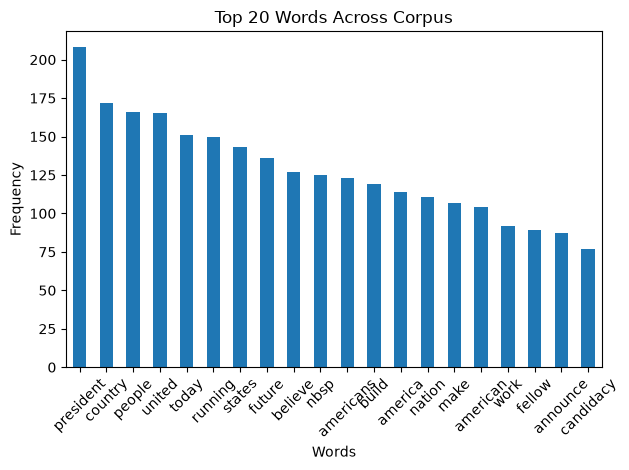

In [10]:
word_counts.head(20).plot(kind='bar')
plt.title("Top 20 Words Across Corpus")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Most important words per document 

In [11]:
def top_words_per_doc(df, n=20):
    results = {}
    for doc in df.index:
        top_words = df.loc[doc].sort_values(ascending=False).head(n)
        results[doc] = top_words[top_words > 0]
    return results

per_doc = top_words_per_doc(bow_df)

In [12]:
# Example: show one document
example_doc = list(per_doc.keys())[0]
print(f"\nTop words in {example_doc}:")
print(per_doc[example_doc])


Top words in AI_responses.txt:
today        120
future       117
united       114
president    107
build        105
believe       99
states        98
americans     97
nbsp          89
american      86
people        86
country       81
running       79
nation        77
fellow        73
work          65
announce      63
candidacy     63
america       61
economy       57
Name: AI_responses.txt, dtype: int64


In [13]:
# Example: show one document
example_doc = list(per_doc.keys())[1]
print(f"\nTop words in {example_doc}:")
print(per_doc[example_doc])


Top words in human_responses.txt:
president    101
country       91
people        80
make          72
running       71
america       53
united        51
states        45
want          45
better        36
nbsp          36
vote          36
nation        34
today         31
change        30
support       29
bring         28
believe       28
hello         28
work          27
Name: human_responses.txt, dtype: int64


## 8. Try with bigrams

In [18]:
vectorizer2 = CountVectorizer(
    strip_accents='unicode',
    stop_words='english',
    ngram_range = (2,2),
    max_df=2,
    min_df=1
)

X2 = vectorizer2.fit_transform(corpus)

feature_names2 = vectorizer2.get_feature_names_out()

bow_df2 = pd.DataFrame(X2.toarray(), columns=feature_names2, index=filenames)

bow_df2.head()

,10 years,100 taxes,15 fellow,20 year,2028 believe,2028 born,2028 election,2028 grateful,2028 presidency,2028 presidential,...,yes true,yesterday candidate,yesterday instead,yoour support,york best,young people,young person,young promising,younger generation,zach president
AI_responses.txt,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,3,0,0,0
human_responses.txt,1,1,0,1,1,1,1,1,1,3,...,1,1,1,1,1,2,0,1,1,1


In [19]:
per_doc2 = top_words_per_doc(bow_df2)

In [20]:
# show one document
example_doc2 = list(per_doc2.keys())[0]
print(f"\nTop words in {example_doc2}:")
print(per_doc2[example_doc2])


Top words in AI_responses.txt:
united states          97
president united       97
fellow americans       72
candidacy president    63
americans today        57
states believe         46
nbsp nbsp              46
announce candidacy     43
running president      38
proud announce         35
brighter future        35
today stand            35
believe country        34
days ahead             31
today proud            29
generations come       27
hard work              25
build economy          25
build stronger         23
best days              22
Name: AI_responses.txt, dtype: int64


In [21]:
# show other document
example_doc2 = list(per_doc2.keys())[1]
print(f"\nTop words in {example_doc2}:")
print(per_doc2[example_doc2])


Top words in human_responses.txt:
running president      55
united states          45
president united       31
nbsp nbsp              16
candidacy president    13
fellow americans       13
states america         12
make country           12
announce running       10
want make               9
announce candidacy      9
country better          9
better place            8
believe country         8
country needs           8
make america            8
announcing running      7
american people         7
today announcing        7
president want          6
Name: human_responses.txt, dtype: int64
